# Árboles de decisión para regresión con Iris

Universidad Cooperativa de Colombia · Seguimiento evaluativo del 10 %

| Dato | Detalle |
|---|---|
| Estudiante | Luis Miguel Muñoz Rendón |
| Docente | Luis Miguel Gómez Meneses |
| Asignatura | Analítica de Datos · Ingeniería de Software |
| Fecha | Octubre de 2026 |

Objetivo: predecir la longitud del pétalo (cm) con un árbol de regresión, elegir su profundidad con validación cruzada y evaluarlo una sola vez en datos de prueba.

## 1. Consulta del método

### 1.1 Árbol de regresión

Un árbol de regresión predice un número haciendo preguntas del tipo "¿esta variable es menor o igual a cierto valor?". Cada dato baja por las ramas según sus respuestas hasta llegar a una hoja. Para construirlo, scikit-learn (algoritmo CART) elige en cada nodo el corte que más reduce el error cuadrático (`criterion="squared_error"`) en los dos grupos que resultan.

### 1.2 Pregunta guía: ¿por qué es un problema de regresión y qué representa el valor de una hoja?

Es regresión porque la longitud del pétalo es una medida continua en centímetros; predecir la especie sería clasificación. El valor de una hoja es el promedio de y de las flores de entrenamiento que llegaron a ella, y esa es la predicción para cualquier flor nueva que caiga ahí. Por eso las predicciones son escalonadas: hay tantos valores posibles como hojas.

### 1.3 Pregunta guía: ¿en qué se diferencia de un árbol de clasificación y de una regresión lineal?

| Aspecto | Árbol de clasificación | Árbol de regresión | Regresión lineal |
|---|---|---|---|
| Qué predice | Una categoría | Un número | Un número |
| Cómo predice | Clase más frecuente en la hoja | Promedio de y en la hoja | Ecuación $\hat{y}=b_0+b_1x_1+b_2x_2+b_3x_3$ |
| Criterio de ajuste | Gini o entropía | Error cuadrático | Mínimos cuadrados |
| Forma de la predicción | Una de las clases vistas | Escalonada, no extrapola | Continua, puede extrapolar |

A diferencia de la regresión lineal, el árbol no supone una relación lineal: divide el espacio en rectángulos y predice una constante en cada uno. Así capta relaciones no lineales y no necesita escalar las variables.

### 1.4 `max_depth` y sobreajuste

`max_depth` es un hiperparámetro que limita los niveles de preguntas del árbol (con profundidad $d$ puede tener hasta $2^d$ hojas; `None` no pone límite). Con poca profundidad el modelo es demasiado simple (subajuste). Con mucha, las hojas quedan con una o dos flores y el árbol memoriza el entrenamiento (sobreajuste): su error de entrenamiento cae casi a cero, pero empeora con datos nuevos. Por eso la profundidad se elige con validación cruzada y no con el error de entrenamiento.

*Fuentes: documentación de scikit-learn; James et al. (2021, cap. 8); Breiman et al. (1984). Ver sección 7.*

## 2. Carga y exploración de los datos

Cargo las librerías y el conjunto Iris. Renombro las columnas al español; solo cambian los nombres.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Estilo sencillo para los gráficos
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#8a8984", "#2b2b2a"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10,
})

print("Versión de scikit-learn:", sklearn.__version__)

Versión de scikit-learn: 1.9.1


In [2]:
iris = load_iris(as_frame=True)

datos = iris.frame.rename(columns={
    "sepal length (cm)": "largo_sepalo",
    "sepal width (cm)": "ancho_sepalo",
    "petal length (cm)": "largo_petalo",
    "petal width (cm)": "ancho_petalo",
    "target": "especie",
})

print("Dimensiones:", datos.shape)
datos.head()

Dimensiones: (150, 5)


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Hay 150 flores y 5 columnas: cuatro medidas en centímetros y la especie.

In [3]:
for codigo, nombre in enumerate(iris.target_names):
    cantidad = (datos["especie"] == codigo).sum()
    print(f"especie {codigo} = {nombre}: {cantidad} flores")

tipos = pd.DataFrame({
    "tipo en pandas": datos.dtypes.astype(str),
    "tipo de variable": ["numérica continua (cm)"] * 4 + ["categórica (códigos 0, 1, 2)"],
    "papel en este trabajo": ["predictor (X)", "predictor (X)", "objetivo (y)",
                              "predictor (X)", "excluida"],
})
tipos

especie 0 = setosa: 50 flores
especie 1 = versicolor: 50 flores
especie 2 = virginica: 50 flores


,tipo en pandas,tipo de variable,papel en este trabajo
largo_sepalo,float64,numérica continua (cm),predictor (X)
ancho_sepalo,float64,numérica continua (cm),predictor (X)
largo_petalo,float64,numérica continua (cm),objetivo (y)
ancho_petalo,float64,numérica continua (cm),predictor (X)
especie,int64,"categórica (códigos 0, 1, 2)",excluida


Las cuatro medidas son numéricas continuas. La especie es categórica (sus números son solo códigos) y queda fuera del modelo; solo la uso al final para interpretar errores.

In [4]:
medidas = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo"]
datos[medidas].describe().round(2)

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


El largo del pétalo es la medida que más varía (de 1,0 a 6,9 cm). Su promedio (3,76 cm) queda por debajo de la mediana (4,35 cm) porque hay un grupo de flores con pétalos muy cortos. No hay valores fuera de lo razonable.

In [5]:
print("Valores faltantes por columna:")
print(datos.isnull().sum().to_string())
print("\nFilas duplicadas:", datos.duplicated().sum())

datos[datos.duplicated(keep=False)]

Valores faltantes por columna:
largo_sepalo    0
ancho_sepalo    0
largo_petalo    0
ancho_petalo    0
especie         0

Filas duplicadas: 1


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,especie
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


No hay faltantes. Hay un duplicado (flores 101 y 142), pero no lo elimino: con medidas de 0,1 cm de precisión es normal que dos flores midan igual, y no hay indicio de error. Tampoco transformo variables, porque todas están en centímetros y el árbol no necesita escalado.

In [6]:
datos[medidas].corr().round(3)

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
largo_sepalo,1.000,-0.118,0.872,0.818
ancho_sepalo,-0.118,1.000,-0.428,-0.366
largo_petalo,0.872,-0.428,1.000,0.963
ancho_petalo,0.818,-0.366,0.963,1.000


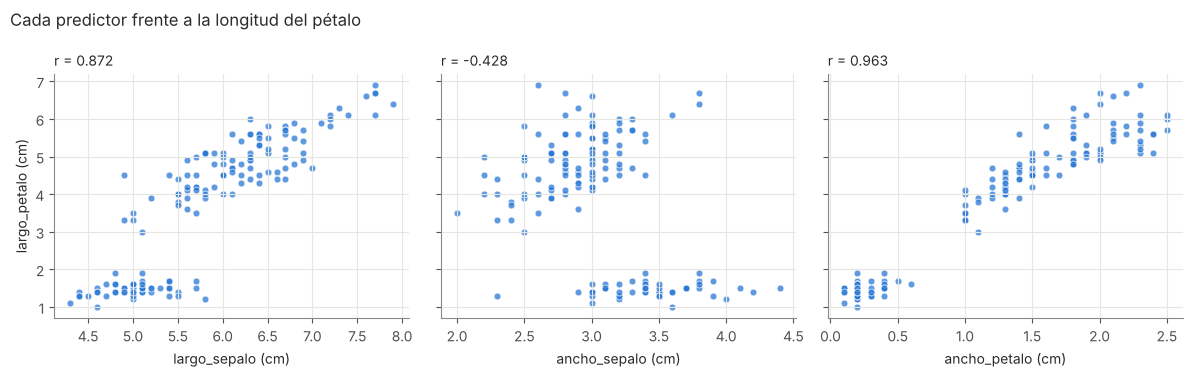

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)

for eje, columna in zip(ejes, ["largo_sepalo", "ancho_sepalo", "ancho_petalo"]):
    r = datos[columna].corr(datos["largo_petalo"])
    eje.scatter(datos[columna], datos["largo_petalo"], s=24, color=AZUL,
                alpha=0.75, edgecolor="white", linewidth=0.6)
    eje.set_xlabel(f"{columna} (cm)")
    eje.set_title(f"r = {r:.3f}", loc="left", fontsize=10, color=TINTA)

ejes[0].set_ylabel("largo_petalo (cm)")
fig.suptitle("Cada predictor frente a la longitud del pétalo", x=0.01, ha="left",
             fontsize=12, color=TINTA)
plt.tight_layout()
plt.show()

El ancho del pétalo tiene una relación casi lineal con el largo (r = 0,963), y el largo del sépalo también se relaciona bastante (0,872). El grupo de abajo a la izquierda son las setosas. Se espera que el árbol use sobre todo el ancho del pétalo.

## 3. Definición de X e y y separación de los datos

y es el largo del pétalo y X son las otras tres medidas. Como `iris.target` contiene la especie, y se toma de la columna `largo_petalo`.

In [8]:
predictores = ["largo_sepalo", "ancho_sepalo", "ancho_petalo"]
objetivo = "largo_petalo"

X = datos[predictores]
y = datos[objetivo]

# Comprobaciones: el objetivo no está en X y la especie no se usa
assert objetivo not in X.columns
assert "especie" not in X.columns

print("X:", X.shape, "->", list(X.columns))
print("y:", y.shape, "->", y.name)

X: (150, 3) -> ['largo_sepalo', 'ancho_sepalo', 'ancho_petalo']
y: (150,) -> largo_petalo


Separo una sola vez 80 % para entrenamiento y 20 % para prueba, con `random_state=42` y sin estratificar, porque y es continua.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} flores")
print(f"Prueba:        {X_test.shape[0]} flores")
print(f"\nPromedio de y en entrenamiento: {y_train.mean():.3f} cm")
print(f"Promedio de y en prueba:        {y_test.mean():.3f} cm")

Entrenamiento: 120 flores
Prueba:        30 flores

Promedio de y en entrenamiento: 3.727 cm
Promedio de y en prueba:        3.883 cm


Quedan 120 flores para entrenar y 30 para prueba, con promedios de y parecidos (3,73 y 3,88 cm). La prueba no se vuelve a usar hasta la sección 5.

## 4. Comparación de profundidades con validación cruzada

Comparo `max_depth` = 1, 2, 3, 4 y `None` con `KFold` de 5 particiones (`shuffle=True`, `random_state=42`), solo sobre entrenamiento. Como `kf` se crea una vez, todos los modelos usan las mismas particiones. scikit-learn devuelve el MAE con signo negativo (`neg_mean_absolute_error`), así que le cambio el signo. El MAE de entrenamiento lo incluyo solo para ver el sobreajuste.

In [10]:
profundidades = [1, 2, 3, 4, None]
kf = KFold(n_splits=5, shuffle=True, random_state=42)   # mismas particiones para todos

filas = []
mae_por_particion = {}

for profundidad in profundidades:
    arbol = DecisionTreeRegressor(
        criterion="squared_error", max_depth=profundidad, random_state=42
    )
    resultado = cross_validate(
        arbol, X_train, y_train, cv=kf,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
    )
    mae_validacion = -resultado["test_score"]      # cambio de signo: MAE positivo
    mae_entrenamiento = -resultado["train_score"]

    nombre = "None" if profundidad is None else str(profundidad)
    mae_por_particion[nombre] = mae_validacion
    filas.append({
        "max_depth": nombre,
        "MAE promedio (cm)": mae_validacion.mean(),
        "Desv. estándar (cm)": mae_validacion.std(),   # desviación de los 5 MAE
        "MAE en entrenamiento (cm)": mae_entrenamiento.mean(),
    })

tabla_cv = pd.DataFrame(filas)
tabla_cv.round(4)

,max_depth,MAE promedio (cm),Desv. estándar (cm),MAE en entrenamiento (cm)
0,1,0.4924,0.1312,0.4866
1,2,0.3600,0.0733,0.3237
2,3,0.2863,0.0465,0.2267
3,4,0.2617,0.0374,0.1572
4,None,0.2792,0.0545,0.0044


MAE de validación en cada partición:

In [11]:
tabla_particiones = pd.DataFrame(
    mae_por_particion, index=[f"Partición {i}" for i in range(1, 6)]
)
tabla_particiones.columns.name = "max_depth"
tabla_particiones.round(4)

max_depth,1,2,3,4,None
Partición 1,0.4833,0.3103,0.2635,0.2648,0.2792
Partición 2,0.5544,0.3567,0.2966,0.2842,0.3083
Partición 3,0.3866,0.2545,0.2141,0.1909,0.2042
Partición 4,0.3323,0.4574,0.3548,0.2990,0.3625
Partición 5,0.7052,0.4212,0.3027,0.2698,0.2417


In [12]:
# La tabla está ordenada de menor a mayor profundidad. idxmin() devuelve la primera
# fila con el MAE mínimo, así que si hubiera empate se queda con la menor profundidad.
mae_minimo = tabla_cv["MAE promedio (cm)"].min()
empatados = (tabla_cv["MAE promedio (cm)"] == mae_minimo).sum()

indice_mejor = tabla_cv["MAE promedio (cm)"].idxmin()
mejor_profundidad = profundidades[indice_mejor]

print("Configuraciones con el MAE mínimo:", empatados)
print("Profundidad seleccionada: max_depth =", mejor_profundidad)
print(f"MAE de validación: {tabla_cv.loc[indice_mejor, 'MAE promedio (cm)']:.4f} cm "
      f"(desv. estándar {tabla_cv.loc[indice_mejor, 'Desv. estándar (cm)']:.4f} cm)")

Configuraciones con el MAE mínimo: 1
Profundidad seleccionada: max_depth = 4
MAE de validación: 0.2617 cm (desv. estándar 0.0374 cm)


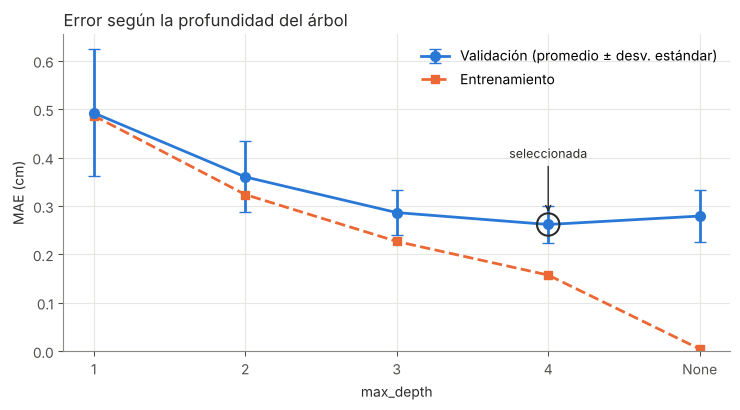

In [13]:
posiciones = np.arange(len(profundidades))
fig, eje = plt.subplots(figsize=(7.5, 4.2))

validacion = eje.errorbar(posiciones, tabla_cv["MAE promedio (cm)"],
                          yerr=tabla_cv["Desv. estándar (cm)"], marker="o", markersize=7,
                          linewidth=2, capsize=4, color=AZUL,
                          label="Validación (promedio ± desv. estándar)")
entrenamiento, = eje.plot(posiciones, tabla_cv["MAE en entrenamiento (cm)"], marker="s",
                          markersize=6, linewidth=2, linestyle="--", color=NARANJA,
                          label="Entrenamiento")

# Resaltar la profundidad seleccionada
mae_elegido = tabla_cv.loc[indice_mejor, "MAE promedio (cm)"]
eje.scatter([indice_mejor], [mae_elegido], s=260, facecolors="none", edgecolors=TINTA,
            linewidths=1.5, zorder=4)
eje.annotate("seleccionada", (indice_mejor, mae_elegido), xytext=(0, 48),
             textcoords="offset points", ha="center", fontsize=9, color=TINTA,
             arrowprops=dict(arrowstyle="->", color=TINTA, shrinkB=9))

eje.set_xticks(posiciones)
eje.set_xticklabels(tabla_cv["max_depth"])
eje.set_xlabel("max_depth")
eje.set_ylabel("MAE (cm)")
eje.set_ylim(bottom=0)
eje.set_title("Error según la profundidad del árbol", loc="left", fontsize=12, color=TINTA)
eje.legend(handles=[validacion, entrenamiento], frameon=False)
plt.tight_layout()
plt.show()

### 4.1 Profundidad seleccionada

Gana `max_depth=4`, con un MAE de 0,262 cm (desviación de 0,037 cm). No hubo empate; si lo hubiera, `idxmin()` toma la primera fila, que es la menor profundidad.

### 4.2 Pregunta guía: ¿aumentar la profundidad siempre redujo el error de validación?

No. El MAE bajó de 0,492 cm (profundidad 1) a 0,262 cm (profundidad 4), pero subió a 0,279 cm con `None`. Ese árbol tiene un MAE de entrenamiento de 0,004 cm: memorizó los datos y predice peor las flores nuevas, que es el sobreajuste. Además, la mejora de 3 a 4 fue pequeña (0,025 cm) y la profundidad 4 no ganó en todas las particiones, por eso se decide con el promedio.

## 5. Entrenamiento y evaluación final

Entreno el árbol con la profundidad elegida (`mejor_profundidad`) usando las 120 flores de entrenamiento.

In [14]:
modelo_final = DecisionTreeRegressor(
    criterion="squared_error", max_depth=mejor_profundidad, random_state=42
)
modelo_final.fit(X_train, y_train)

print("Profundidad del árbol:", modelo_final.get_depth())
print("Número de hojas:", modelo_final.get_n_leaves())

Profundidad del árbol: 4
Número de hojas: 14


In [15]:
print(export_text(modelo_final, feature_names=predictores, decimals=2))

|--- ancho_petalo <= 0.80
|   |--- largo_sepalo <= 4.75
|   |   |--- ancho_sepalo <= 3.50
|   |   |   |--- ancho_petalo <= 0.15
|   |   |   |   |--- value: [1.10]
|   |   |   |--- ancho_petalo >  0.15
|   |   |   |   |--- value: [1.36]
|   |   |--- ancho_sepalo >  3.50
|   |   |   |--- value: [1.00]
|   |--- largo_sepalo >  4.75
|   |   |--- largo_sepalo <= 4.85
|   |   |   |--- value: [1.75]
|   |   |--- largo_sepalo >  4.85
|   |   |   |--- ancho_petalo <= 0.35
|   |   |   |   |--- value: [1.44]
|   |   |   |--- ancho_petalo >  0.35
|   |   |   |   |--- value: [1.60]
|--- ancho_petalo >  0.80
|   |--- ancho_petalo <= 1.55
|   |   |--- ancho_petalo <= 1.15
|   |   |   |--- largo_sepalo <= 5.30
|   |   |   |   |--- value: [3.28]
|   |   |   |--- largo_sepalo >  5.30
|   |   |   |   |--- value: [3.82]
|   |   |--- ancho_petalo >  1.15
|   |   |   |--- largo_sepalo <= 5.95
|   |   |   |   |--- value: [4.18]
|   |   |   |--- largo_sepalo >  5.95
|   |   |   |   |--- value: [4.65]
|   |---

El primer corte (ancho del pétalo ≤ 0,80 cm) separa a las setosas. Después el árbol usa sobre todo el ancho del pétalo y el largo del sépalo.

In [16]:
importancia = pd.Series(modelo_final.feature_importances_, index=predictores, name="importancia")
importancia.sort_values(ascending=False).round(3)

ancho_petalo    0.964
largo_sepalo    0.036
ancho_sepalo    0.000
Name: importancia, dtype: float64

El ancho del pétalo aporta el 96 % de la importancia, así que el modelo depende casi solo de esa medida.

Para comprobar qué representa cada hoja, comparo el promedio real de y de las flores de entrenamiento en cada hoja con el valor que guarda el árbol:

In [17]:
hoja_de_cada_flor = modelo_final.apply(X_train)   # número de hoja de cada flor

resumen_hojas = (
    pd.DataFrame({"hoja": hoja_de_cada_flor, "largo_petalo": y_train.values})
    .groupby("hoja")["largo_petalo"]
    .agg(flores="count", promedio_real="mean")
)
resumen_hojas["valor_de_la_hoja"] = modelo_final.tree_.value[resumen_hojas.index, 0, 0]
resumen_hojas["coinciden"] = np.isclose(resumen_hojas["promedio_real"],
                                        resumen_hojas["valor_de_la_hoja"])
resumen_hojas.round(4)

,flores,promedio_real,valor_de_la_hoja,coinciden
hoja,,,,
4,1,1.1000,1.1000,True
5,8,1.3625,1.3625,True
6,1,1.0000,1.0000,True
8,2,1.7500,1.7500,True
10,21,1.4429,1.4429,True
11,7,1.6000,1.6000,True
15,4,3.2750,3.2750,True
16,5,3.8200,3.8200,True
18,13,4.1769,4.1769,True


Coinciden en las 14 hojas: el valor de una hoja es el promedio de y de sus flores de entrenamiento. Algunas hojas tienen una sola flor.

### 5.1 Métricas en prueba

Evalúo una sola vez sobre prueba. Como referencia, calculo también el MAE de predecir siempre el promedio.

In [18]:
y_pred = modelo_final.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Referencia: predecir siempre el promedio de entrenamiento
mae_promedio = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

print(f"MAE  (prueba): {mae:.4f} cm")
print(f"RMSE (prueba): {rmse:.4f} cm")
print(f"R²   (prueba): {r2:.4f}")
print(f"\nMAE si siempre se predice el promedio ({y_train.mean():.2f} cm): {mae_promedio:.4f} cm")

MAE  (prueba): 0.2385 cm
RMSE (prueba): 0.2906 cm
R²   (prueba): 0.9742

MAE si siempre se predice el promedio (3.73 cm): 1.6429 cm


- MAE = 0,239 cm: en promedio la predicción se desvía unos 2,4 mm del valor real. Prediciendo siempre el promedio sería 1,64 cm.
- RMSE = 0,291 cm: castiga más los errores grandes. Queda cerca del MAE, así que hay pocos errores grandes.
- R² = 0,974: el modelo explica cerca del 97 % de la variación del largo del pétalo. No es un porcentaje de predicciones correctas.

### 5.2 Pregunta guía: ¿qué significa el MAE en centímetros y cómo se compara con el de prueba?

El MAE está en la misma unidad de y, así que se lee directamente como un error promedio en centímetros. En validación fue 0,262 cm y en prueba 0,239 cm. La diferencia (0,023 cm) es menor que la desviación entre particiones, de modo que la validación cruzada estimó bien el desempeño. Con solo 30 flores de prueba, no interpreto esa diferencia como una mejora real.

### 5.3 Predicciones sobre prueba

Ordenadas de mayor a menor error (el índice es el número de la flor):

In [19]:
tabla_prueba = pd.DataFrame({
    "real (cm)": y_test,
    "predicho (cm)": y_pred,
    "error absoluto (cm)": np.abs(y_test - y_pred),
}).sort_values("error absoluto (cm)", ascending=False, kind="stable")
tabla_prueba.index.name = "flor"

tabla_prueba.round(3)

,real (cm),predicho (cm),error absoluto (cm)
flor,,,
56,4.7,5.441,0.741
64,3.6,4.177,0.577
143,5.9,5.441,0.459
118,6.9,6.525,0.375
104,5.8,5.441,0.359
108,5.8,5.441,0.359
12,1.4,1.750,0.350
45,1.4,1.750,0.350
141,5.1,5.441,0.341


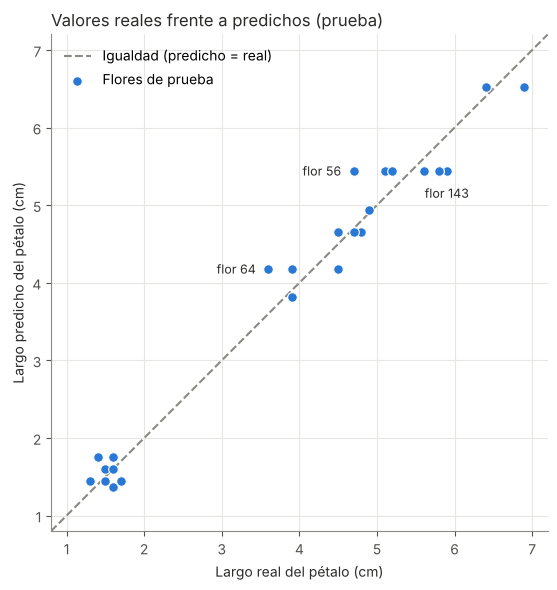

In [20]:
fig, eje = plt.subplots(figsize=(6, 6))
limites = [0.8, 7.2]

eje.plot(limites, limites, linestyle="--", color=GRIS, linewidth=1.5,
         label="Igualdad (predicho = real)")
eje.scatter(tabla_prueba["real (cm)"], tabla_prueba["predicho (cm)"], s=48, color=AZUL,
            edgecolor="white", linewidth=0.8, zorder=3, label="Flores de prueba")

# Etiquetas para los tres errores más grandes (posición elegida para no tapar otros puntos)
posiciones_etiqueta = [((-9, 0), "right"), ((-9, 0), "right"), ((0, -16), "center")]
for (flor, fila), (desplazamiento, alineacion) in zip(tabla_prueba.head(3).iterrows(),
                                                      posiciones_etiqueta):
    eje.annotate(f"flor {flor}", (fila["real (cm)"], fila["predicho (cm)"]),
                 xytext=desplazamiento, textcoords="offset points", ha=alineacion,
                 va="center", fontsize=9, color=TINTA)

eje.set_xlim(limites)
eje.set_ylim(limites)
eje.set_aspect("equal")
eje.set_xlabel("Largo real del pétalo (cm)")
eje.set_ylabel("Largo predicho del pétalo (cm)")
eje.set_title("Valores reales frente a predichos (prueba)", loc="left", fontsize=12, color=TINTA)
eje.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Los puntos quedan cerca de la línea de igualdad. Las filas horizontales son flores de una misma hoja con la misma predicción; por ejemplo, 9 flores reciben 5,44 cm aunque miden entre 4,7 y 5,9 cm.

### 5.4 Errores más grandes

Agrego los predictores y la especie, esta última solo como referencia (el modelo no la usa):

In [21]:
nombres_especie = dict(enumerate(iris.target_names))

mayores = tabla_prueba.head(5).join(X_test)
mayores["especie (solo referencia)"] = datos.loc[mayores.index, "especie"].map(nombres_especie)
mayores.round(3)

,real (cm),predicho (cm),error absoluto (cm),largo_sepalo,ancho_sepalo,ancho_petalo,especie (solo referencia)
flor,,,,,,,
56,4.7,5.441,0.741,6.3,3.3,1.6,versicolor
64,3.6,4.177,0.577,5.6,2.9,1.3,versicolor
143,5.9,5.441,0.459,6.8,3.2,2.3,virginica
118,6.9,6.525,0.375,7.7,2.6,2.3,virginica
104,5.8,5.441,0.359,6.5,3.0,2.2,virginica


- Flor 56 (0,74 cm): versicolor con un pétalo ancho para su especie (1,6 cm). Cayó en la hoja de 5,44 cm, donde 16 de las 17 flores de entrenamiento son virginicas, y quedó sobreestimada.
- Flor 64 (0,58 cm): su pétalo es corto (3,6 cm) para su ancho; en su hoja, todas las flores de entrenamiento medían entre 3,9 y 4,5 cm.
- Flor 143 (0,46 cm): virginica de 5,9 cm que quedó subestimada en esa misma hoja de 5,44 cm.
- Flor 118 (0,38 cm): mide 6,9 cm, y el árbol no puede predecir más de 6,53 cm.

Los errores grandes están en versicolor y virginica, donde sus medidas se traslapan. No cambio la profundidad por esto: usar la prueba para ajustar el modelo haría que su error dejara de ser una estimación honesta.

## 6. Limitaciones y conclusión

### 6.1 Pregunta guía: ¿por qué se reservaron los datos de prueba y qué limitaciones tiene el modelo?

La prueba se reservó para medir el desempeño con flores que el modelo no usó ni para entrenar ni para elegir la profundidad. Si la hubiera usado para escoger, el error reportado sería optimista.

Limitaciones:

- Solo puede dar 14 valores distintos (predicción escalonada).
- No extrapola: nunca predice más de 6,53 cm.
- Depende casi por completo del ancho del pétalo.
- Hay pocos datos (120 para entrenar y 30 para probar). Las diferencias entre las profundidades 3, 4 y `None` son menores que la variación entre particiones, así que con otra división podría ganar otra profundidad.
- Solo aprendió de tres especies de Iris.

### 6.2 Conclusión

Adapté Iris a un problema de regresión para predecir el largo del pétalo a partir de las otras tres medidas, sin usar la especie. Con validación cruzada de 5 particiones sobre entrenamiento, la profundidad con menor MAE fue 4 (0,262 cm); el árbol sin límite memorizó el entrenamiento y empeoró en validación, lo que muestra el sobreajuste. En la prueba, usada una sola vez, el modelo obtuvo un MAE de 0,239 cm, un RMSE de 0,291 cm y un R² de 0,974, resultados coherentes con la validación. Los errores más grandes aparecen donde versicolor y virginica se traslapan, y su principal limitación es que predice por escalones y no extrapola. Un árbol de profundidad moderada funciona muy bien para esta medida, apoyado casi por completo en el ancho del pétalo.

## 7. Referencias

- Breiman, L., Friedman, J. H., Olshen, R. A. y Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
- Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics, 7*(2), 179-188.
- James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.), cap. 8. Springer. https://www.statlearning.com
- scikit-learn. *Decision Trees*. https://scikit-learn.org/stable/modules/tree.html
- scikit-learn. *DecisionTreeRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
- scikit-learn. *Cross-validation: evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html
- scikit-learn. *KFold*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html
- scikit-learn. *Metrics and scoring: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html